<a href="https://colab.research.google.com/github/jashwanth336/Airport-Flight-Information-Portal/blob/main/plant_disease_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌿 Plant Disease Detection using CNN (Leaf Images)
Dataset: **PlantVillage** (~54,000 leaf images, 38 classes) loaded automatically via TensorFlow Datasets, so no Kaggle account is needed.

**Before running:** Runtime → Change runtime type → **T4 GPU**.

In [ ]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load dataset (80% train / 10% val / 10% test)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.TIAWAY_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold',

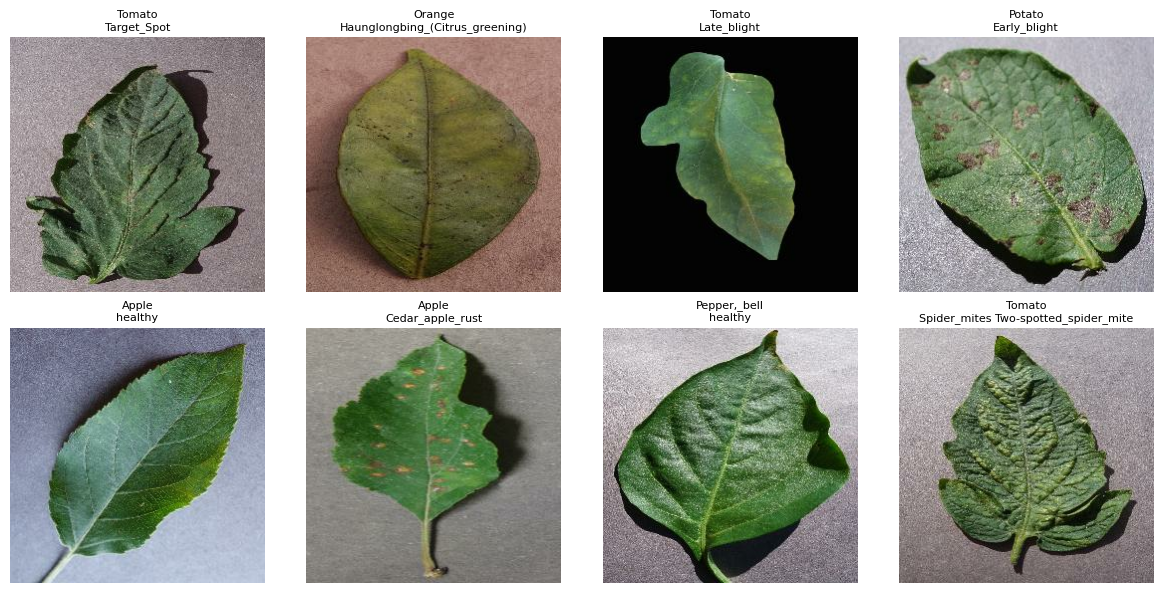

In [ ]:
!pip install -q importlib_resources

import tensorflow_datasets as tfds

(ds_train, ds_val, ds_test), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    with_info=True,
)
class_names = info.features["label"].names
NUM_CLASSES = len(class_names)
print("Classes:", NUM_CLASSES)
print(class_names)

# Preview some images
plt.figure(figsize=(12, 6))
for i, (img, lbl) in enumerate(ds_train.take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(class_names[lbl.numpy()].replace("___", "\n"), fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

## 2. Preprocessing + augmentation

In [ ]:
IMG_SIZE = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def prep(img, lbl):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.float32), lbl   # keep 0-255; scaling happens inside the model

train_ds = ds_train.map(prep, AUTOTUNE).shuffle(2000).batch(BATCH).prefetch(AUTOTUNE)
val_ds   = ds_val.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
test_ds  = ds_test.map(prep, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name="augmentation")

## 3. Build the CNN
Set `USE_TRANSFER = True` for **MobileNetV2 transfer learning** (high accuracy, ~97-99% in a few epochs).
Set `False` for a **custom CNN built from scratch**.

In [ ]:
USE_TRANSFER = True

if USE_TRANSFER:
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = models.Model(inputs, outputs)
else:
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = layers.Rescaling(1./255)(x)
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Train

In [ ]:
EPOCHS = 8 if USE_TRANSFER else 20

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor="val_accuracy"),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, verbose=1),
    tf.keras.callbacks.ModelCheckpoint("best_model.keras", save_best_only=True, monitor="val_accuracy"),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 117s 74ms/step - accuracy: 0.8199 - loss: 0.6332 - val_accuracy: 0.9090 - val_loss: 0.3032 - learning_rate: 0.0010
Epoch 2/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 100s 72ms/step - accuracy: 0.8973 - loss: 0.3197 - val_accuracy: 0.9241 - val_loss: 0.2368 - learning_rate: 0.0010
Epoch 3/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 101s 72ms/step - accuracy: 0.9082 - loss: 0.2834 - val_accuracy: 0.9284 - val_loss: 0.2145 - learning_rate: 0.0010
Epoch 4/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 100s 73ms/step - accuracy: 0.9126 - loss: 0.2698 - val_accuracy: 0.9267 - val_loss: 0.2231 - learning_rate: 0.0010
Epoch 5/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 101s 73ms/step - accuracy: 0.9150 - loss: 0.2543 - val_accuracy: 0.9330 - val_loss: 0.2076 - learning_rate: 0.0010
Epoch 6/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 143s 74ms/step - accuracy: 0.9163 - loss: 0.2572 - val_accuracy: 0.9357 - val_loss: 0.2020 - learning_rate: 0.0010
Epoch 7/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 103s 74ms/step - accura

In [ ]:
# Optional fine-tuning (transfer learning only): unfreezes top layers for extra accuracy
if USE_TRANSFER:
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    ft = model.fit(train_ds, validation_data=val_ds, epochs=4, callbacks=callbacks)
    for k in history.history:
        history.history[k] += ft.history[k]

Epoch 1/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 137s 93ms/step - accuracy: 0.8457 - loss: 0.5950 - val_accuracy: 0.9418 - val_loss: 0.1812 - learning_rate: 1.0000e-05
Epoch 2/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 140s 92ms/step - accuracy: 0.9143 - loss: 0.2670 - val_accuracy: 0.9472 - val_loss: 0.1597 - learning_rate: 1.0000e-05
Epoch 3/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 126s 91ms/step - accuracy: 0.9276 - loss: 0.2156 - val_accuracy: 0.9536 - val_loss: 0.1428 - learning_rate: 1.0000e-05
Epoch 4/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 126s 91ms/step - accuracy: 0.9384 - loss: 0.1820 - val_accuracy: 0.9577 - val_loss: 0.1263 - learning_rate: 1.0000e-05


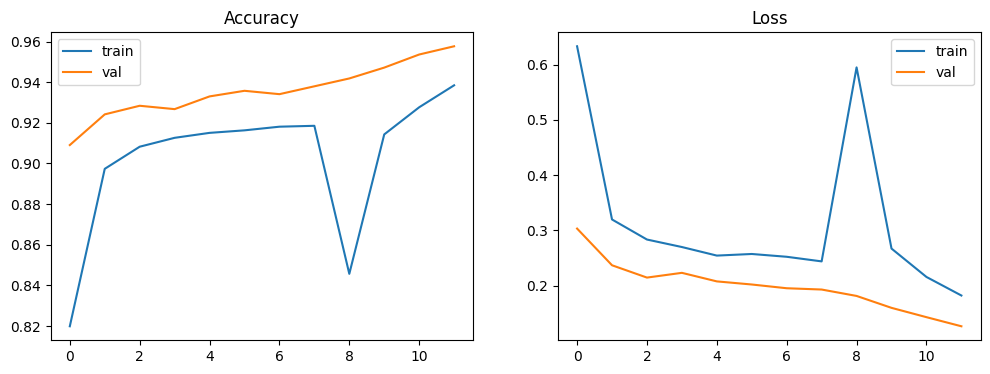

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

## 5. Evaluate on the test set

170/170 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - accuracy: 0.9575 - loss: 0.1302
Test accuracy: 95.75%
170/170 ━━━━━━━━━━━━━━━━━━━━ 12s 61ms/step
                                               precision    recall  f1-score   support

                           Apple___Apple_scab      0.982     0.948     0.965        58
                            Apple___Black_rot      0.985     0.985     0.985        65
                     Apple___Cedar_apple_rust      0.960     0.960     0.960        25
                              Apple___healthy      0.975     0.994     0.984       159
                          Blueberry___healthy      1.000     0.992     0.996       133
                             Cherry___healthy      0.978     0.989     0.983        90
                      Cherry___Powdery_mildew      0.980     0.980     0.980       100
   Corn___Cercospora_leaf_spot Gray_leaf_spot      0.872     0.732     0.796        56
                           Corn___Common_rust      0.992     0.992     0.9

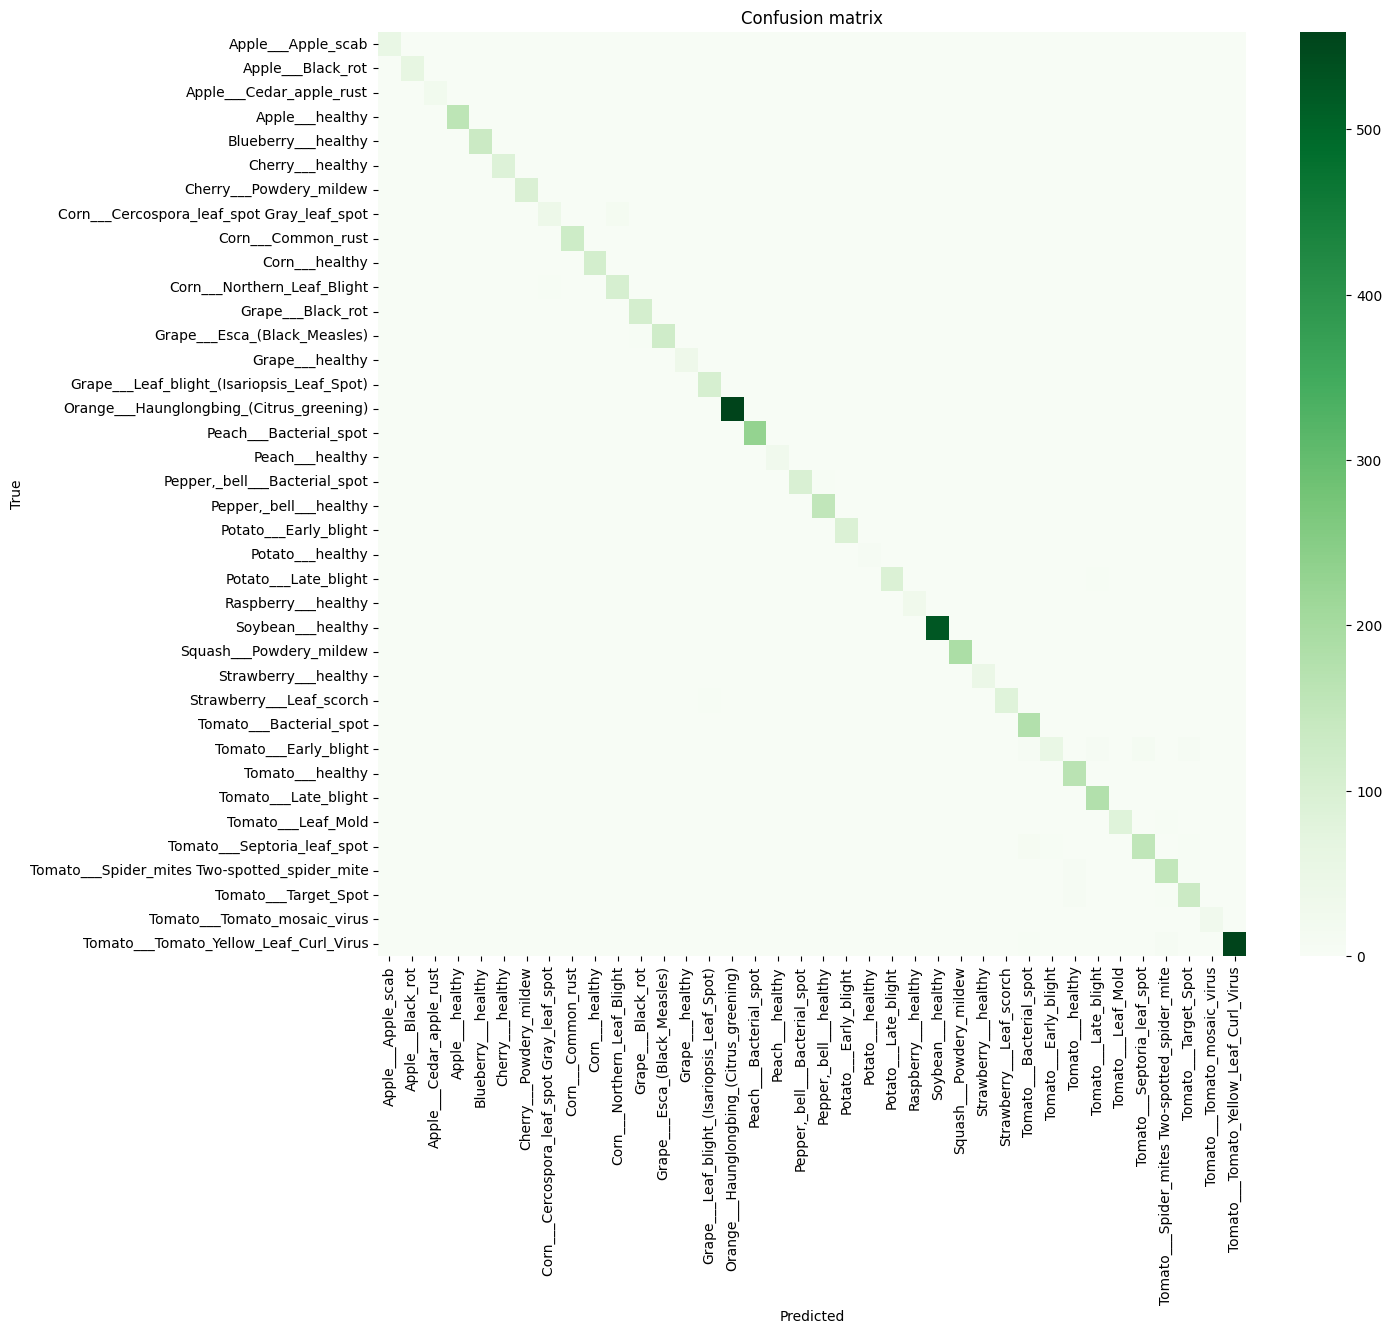

In [ ]:
loss, acc = model.evaluate(test_ds)
print(f"Test accuracy: {acc*100:.2f}%")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

plt.figure(figsize=(14, 12))
sns.heatmap(confusion_matrix(y_true, y_pred), cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.show()

## 6. Save the model

In [ ]:
model.save("plant_disease_model.keras")

import json
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

# from google.colab import files
# files.download("plant_disease_model.keras"); files.download("class_names.json")

## 7. 🔍 Detect disease from your own leaf image
Run the cell, click **Choose Files**, and upload a leaf photo.

Saving images.jpg to images.jpg
 images.jpg


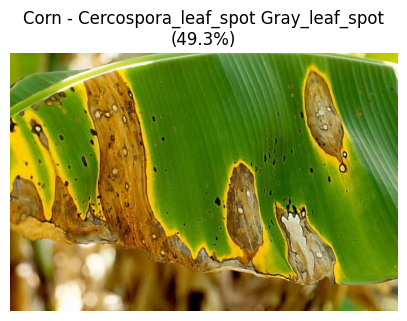

Top predictions:
  Corn___Cercospora_leaf_spot Gray_leaf_spot               49.3%
  Corn___Northern_Leaf_Blight                              48.8%
  Strawberry___Leaf_scorch                                  1.6%

Plant  : Corn
Status : Disease detected ⚠️  Cercospora leaf spot Gray leaf spot


In [ ]:
from google.colab import files
from PIL import Image
import io

def predict_leaf(img_bytes, top_k=3):
    img = Image.open(io.BytesIO(img_bytes)).convert("RGB")
    arr = np.array(img.resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32)
    probs = model.predict(np.expand_dims(arr, 0), verbose=0)[0]
    top = probs.argsort()[::-1][:top_k]

    plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis("off")
    best = class_names[top[0]]
    plt.title(f"{best.replace('___', ' - ')}\n({probs[top[0]]*100:.1f}%)")
    plt.show()

    print("Top predictions:")
    for i in top:
        print(f"  {class_names[i]:55s} {probs[i]*100:5.1f}%")
    plant, _, disease = best.partition("___")
    print("\nPlant  :", plant.replace("_", " "))
    print("Status :", "Healthy ✅" if "healthy" in disease.lower() else f"Disease detected ⚠️  {disease.replace('_', ' ')}")

uploaded = files.upload()
for name, data in uploaded.items():
    print("=" * 60, "\n", name)
    predict_leaf(data)